In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import RandomOverSampler


# Data Info

In [4]:
cols = ['flength' ,"fWidth","fSize" ,"fConc" ,"fConc1","fAsym" ,"fM3Long" ,"fM3Trans","fAlpha","fDist","class"]
df = pd.read_csv('magic04.data',names=cols)
df.head()

,flength,fWidth,fSize,fConc,fConc1,fAsym,fM3Long,fM3Trans,fAlpha,fDist,class
0,28.7967,16.0021,2.6449,0.3918,0.1982,27.7004,22.0110,-8.2027,40.0920,81.8828,g
1,31.6036,11.7235,2.5185,0.5303,0.3773,26.2722,23.8238,-9.9574,6.3609,205.2610,g
2,162.0520,136.0310,4.0612,0.0374,0.0187,116.7410,-64.8580,-45.2160,76.9600,256.7880,g
3,23.8172,9.5728,2.3385,0.6147,0.3922,27.2107,-6.4633,-7.1513,10.4490,116.7370,g
4,75.1362,30.9205,3.1611,0.3168,0.1832,-5.5277,28.5525,21.8393,4.6480,356.4620,g


In [5]:
df['class'].unique()

array(['g', 'h'], dtype=object)

In [6]:
df['class'] = (df['class'] == 'g').astype(int)

In [7]:
df['class'].unique()

array([1, 0])

# Visual Representation

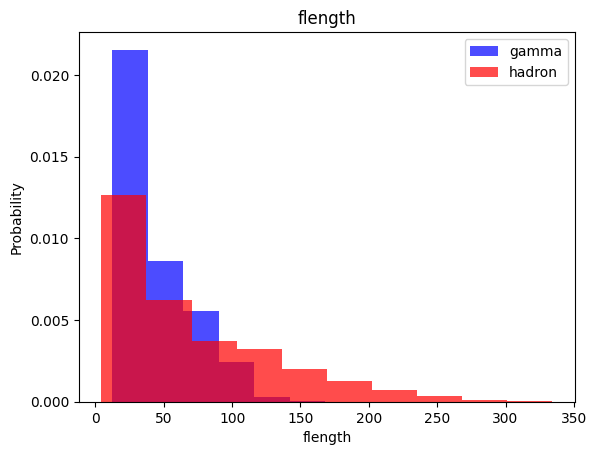

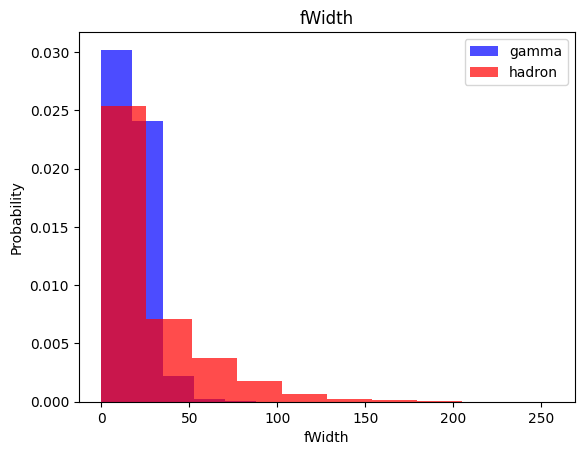

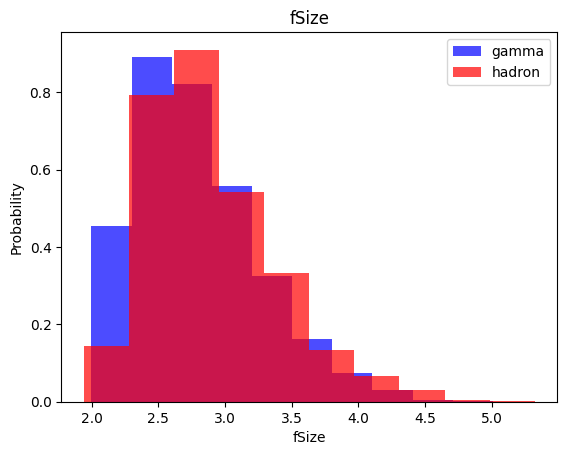

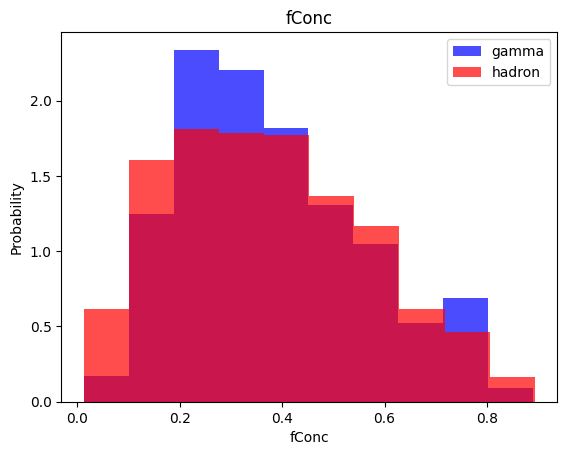

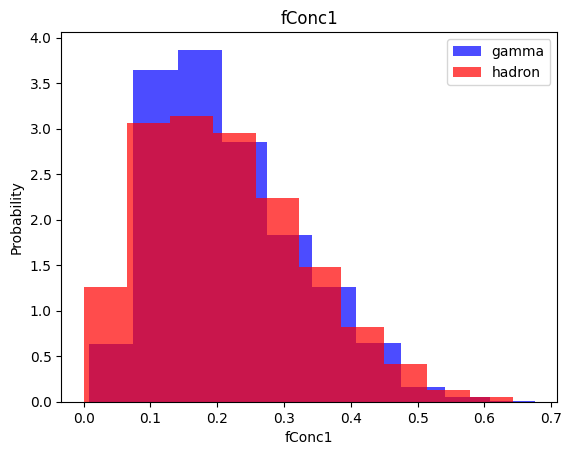

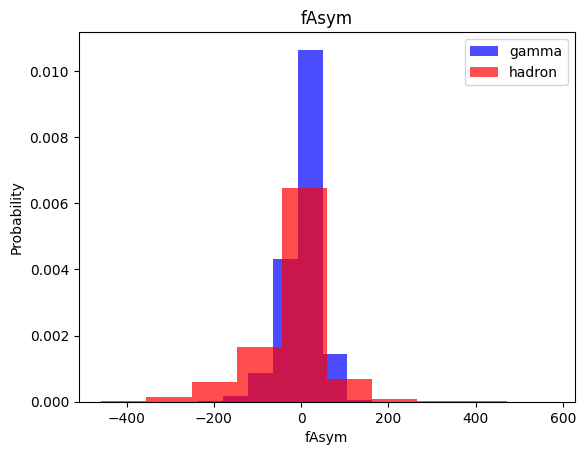

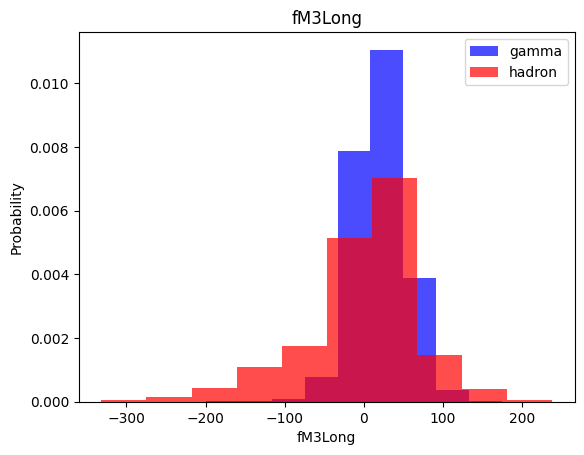

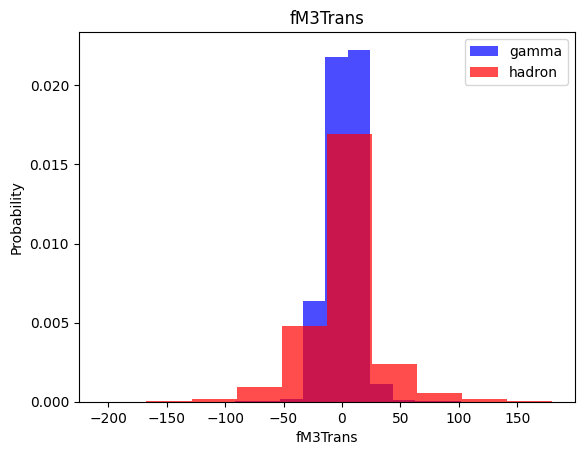

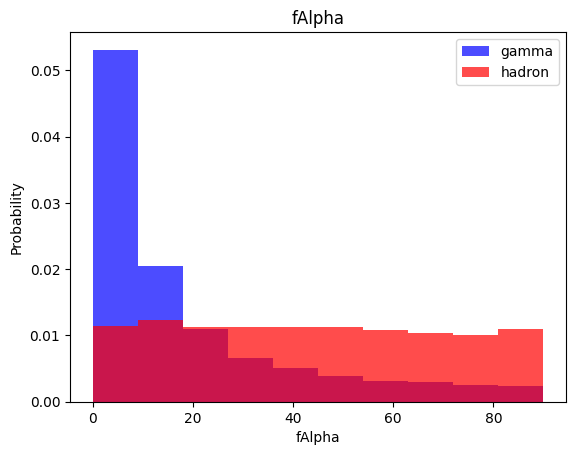

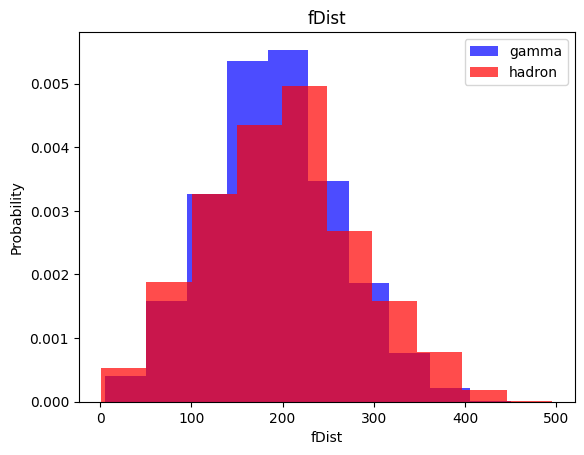

In [8]:
for label in cols[:-1]:
  plt.hist(df[df['class']==1][label],color='blue',label='gamma',alpha=0.7,density=True)
  plt.hist(df[df['class']==0][label],color='red',label='hadron',alpha=0.7,density=True)
  plt.title(label)
  plt.ylabel('Probability')
  plt.xlabel(label)
  plt.legend()
  plt.show()

# Splitting and preprocessing

In [9]:
train, valid, test = np.split(df.sample(frac=1), [int(0.6*len(df)), int(0.8*len(df))])

/usr/local/lib/python3.13/dist-packages/numpy/_core/fromnumeric.py:57: FutureWarning: 'DataFrame.swapaxes' is deprecated and will be removed in a future version. Please use 'DataFrame.transpose' instead.
  return bound(*args, **kwds)


In [10]:
train.shape

(11412, 11)

In [11]:
test.shape

(3804, 11)

In [12]:
valid.shape

(3804, 11)

In [13]:
def scale_dataset(dataframe,oversample=False):
  X = dataframe[dataframe.columns[:-1]].values
  y = dataframe[dataframe.columns[-1]].values
  scaler = StandardScaler()
  X = scaler.fit_transform(X)
  if oversample:
    ros = RandomOverSampler()
    X,y = ros.fit_resample(X,y)
  data = np.hstack((X,np.reshape(y,(-1,1))))
  return data,X,y

In [14]:
len(train[train['class']==1])


7382

In [15]:
len(train[train['class']==0])

4030

In [16]:
train, X_train, y_train = scale_dataset(train, oversample=True)
valid, X_valid, y_valid = scale_dataset(valid, oversample=False)
test, X_test, y_test = scale_dataset(test, oversample=False)

In [17]:
sum(y_train==0)

np.int64(7382)

# KNN (Labs)

In [18]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report

In [19]:
knn_model = KNeighborsClassifier(n_neighbors=5,n_jobs=-1)
knn_model.fit(X_train,y_train)

KNeighborsClassifier(n_jobs=-1)

In [20]:
y_pred = knn_model.predict(X_test)

In [21]:
y_pred

array([1, 1, 0, ..., 0, 1, 1])

In [22]:
classification_report(y_test,y_pred)

'              precision    recall  f1-score   support\n\n           0       0.75      0.74      0.75      1324\n           1       0.86      0.87      0.87      2480\n\n    accuracy                           0.82      3804\n   macro avg       0.81      0.81      0.81      3804\nweighted avg       0.82      0.82      0.82      3804\n'

# Naive Bayes(Labs)


In [23]:
from sklearn.naive_bayes import GaussianNB

In [24]:
nb_model = GaussianNB()
nb_model.fit(X_train,y_train)

GaussianNB()

In [25]:
y_pred = nb_model.predict(X_test)

In [26]:
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.69      0.41      0.51      1324
           1       0.74      0.90      0.81      2480

    accuracy                           0.73      3804
   macro avg       0.71      0.65      0.66      3804
weighted avg       0.72      0.73      0.71      3804



# Logistic Regression (Labs)

In [27]:
from sklearn.linear_model import LogisticRegression

In [28]:
lg_model = LogisticRegression()
lg_model.fit(X_train,y_train)

LogisticRegression()

In [29]:
y_pred = lg_model.predict(X_test)
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.68      0.74      0.71      1324
           1       0.85      0.81      0.83      2480

    accuracy                           0.79      3804
   macro avg       0.77      0.78      0.77      3804
weighted avg       0.79      0.79      0.79      3804



# SVM(Labs)

In [30]:
from sklearn.svm import SVC

In [31]:
svm_model = SVC()
svm_model.fit(X_train,y_train)

SVC()

In [32]:
y_pred = svm_model.predict(X_test)
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.81      0.80      0.80      1324
           1       0.90      0.90      0.90      2480

    accuracy                           0.86      3804
   macro avg       0.85      0.85      0.85      3804
weighted avg       0.86      0.86      0.86      3804



# Neural Network (Labs)

In [33]:
import tensorflow as tf


In [50]:
def history_plot(history):
  fig,(ax1,ax2) = plt.subplots(1,2,figsize=(10,5))
  ax1.plot(history.history['loss'],label='loss')
  ax1.plot(history.history['val_loss'],label='val_loss')
  ax1.set_xlabel('Epoch')
  ax1.set_ylabel('Binary Crossentropy')
  ax1.legend()
  ax1.grid(True)

  ax2.plot(history.history['accuracy'],label='accuracy')
  ax2.plot(history.history['val_accuracy'],label='val_accuracy')
  ax2.set_xlabel('Epoch')
  ax2.set_ylabel('Accuracy')
  ax2.legend()
  ax2.grid(True)

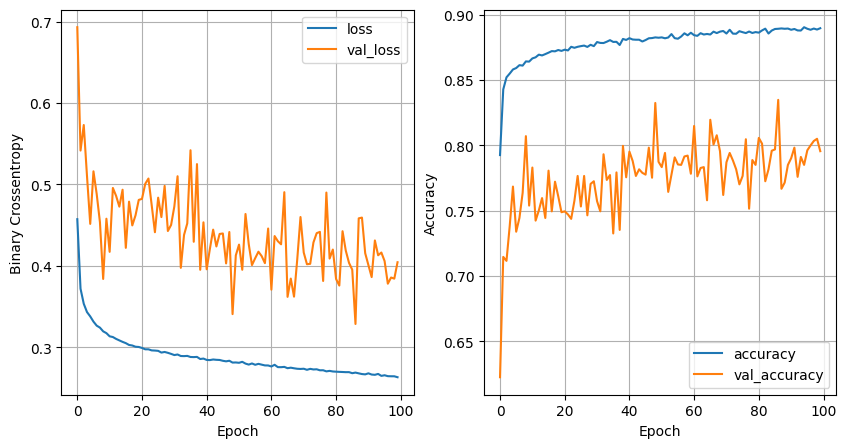

In [51]:
history_plot(history)

In [52]:
def train_model(X_train,y_train,num_nodes,dropout_prob,lr,batch_size,epochs):
 nn_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(10,)),
    tf.keras.layers.Dense(num_nodes,activation='relu'),
    tf.keras.layers.Dropout(dropout_prob),
    tf.keras.layers.Dense(num_nodes,activation='relu'),
    tf.keras.layers.Dropout(dropout_prob),
    tf.keras.layers.Dense(1,activation='sigmoid')
 ])

 nn_model.compile(optimizer=tf.keras.optimizers.Adam(lr),loss='binary_crossentropy',metrics=['accuracy'])
 history = nn_model.fit(X_train,y_train,epochs=epochs,batch_size=batch_size,validation_split=0.2,verbose=False)
 return nn_model,history


In [55]:
nmodel = train_model(X_train,y_train,64,0.2,0.001,128,100)

In [60]:
y_pred = nmodel[0].predict(X_test)
y_pred = (y_pred > 0.5).astype(int).reshape(-1,)
print(classification_report(y_test,y_pred))

119/119 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
              precision    recall  f1-score   support

           0       0.88      0.77      0.82      1324
           1       0.88      0.94      0.91      2480

    accuracy                           0.88      3804
   macro avg       0.88      0.85      0.87      3804
weighted avg       0.88      0.88      0.88      3804

